# Instructions

- This homework assignment is worth **60** points. 
- Please strive for clarity and organization.
- **AI Usage**:
   - AI use is strictly **prohibited** for conceptual exercises.
   - For applied (Python) exercises, you may only use AI for **debugging**. Do not use AI to generate answers.
- **Due Date: October 30, 2026, by 11:59 PM.**

# Exercise 1 (3 points)

Which of the following is a key distinction between non-stochastic and stochastic simulations?

- (a) Use of computer code
- (b) Type of decision-making models
- (c) Use of random variations
- (d) Implementation cost
- (e) All of the above

C)

# Exercise 2 (4 points)

Differentiate between natural and pseudo-random numbers with examples.

Natural random numbers are generated by physical processes that are inherently random, such as rolling dice or atmospheric noise. Pseudo-random numbers are generated by computer algorithms and appear random but are deterministic when the same seed is used.

Rolling a dice generates natural random numbers, while using numpy.random with a fixed seed generates pseudo-random numbers.

# Exercise 3 (3 points)

In a simulation model, what is the purpose of the `seed` in a random number generator?

- (a) To store the model results
- (b) To initialize the simulation model
- (c) To control random number reproducibility
- (d) To scale results
- (e) None of the above

C)

# Exercise 4 (4 points)

List and explain at least three types of shocks that might influence a business system.

1. Demand shock: A sudden increase or decrease in customer demand that affects sales and revenue.
2. Supply shock: A disruption in the supply of raw materials that affects production costs and availability.
3.Economic shock: A change in interest rates, inflation, or unemployment that affects business expenses and consumer spending.

# Exercise 5 (3 points)

What is the key advantage of using simulations for decision-making?

- (a) Eliminates the need for data
- (b) Allows for real-time decisions
- (c) Enables testing of various scenarios without impacting the real system
- (d) Reduces need for programming skills
- (e) None of the above

C)

# Exercise 6 (3 points)

Generate a list of 10 uniformly distributed random numbers between 5 and 15 using `numpy`.

In [1]:
import numpy as np

random_numbers = np.random.uniform(5, 15, 10)
print(random_numbers)

[ 7.12955577 12.67087946  8.7607345  11.35967034 13.69476962  9.25550956
 13.43220338 10.41707847  9.32824125 13.29024313]


# Exercise 7 (5 points)

Simulate the effect of a random shock on quarterly revenue using NumPy. Let base revenue = 100, and the shock follows $N(0, 10)$. Simulate for 8 quarters.

In [2]:
import numpy as np

np.random.seed(42)

base_revenue = 100
shocks = np.random.normal(0, 10, 8)
revenue = base_revenue + shocks

print("Quarterly revenue:", revenue)

Quarterly revenue: [104.96714153  98.61735699 106.47688538 115.23029856  97.65846625
  97.65863043 115.79212816 107.67434729]


# Exercise 8 (7 points)

Write a Python function that runs a simple Monte Carlo simulation to estimate the value of $\pi$ using 10,000 iterations.

In [3]:
import numpy as np

def estimate_pi(n_iterations=10000):
    x = np.random.uniform(0, 1, n_iterations)
    y = np.random.uniform(0, 1, n_iterations)

    inside_circle = (x**2 + y**2) <= 1
    pi_estimate = 4 * np.mean(inside_circle)

    return pi_estimate

print("Estimated value of pi:", estimate_pi())

Estimated value of pi: 3.156


# Exercise 9 (8 points)

A company claims that its online ad converts a visitor into a customer with probability $p = 0.6$. Using the coin-toss example from Chapter 7 as a guide:

- (a) Using `numpy` with `seed = 42`, simulate 10,000 visitors (1 = converts, 0 = does not convert) and compute the proportion that convert.
- (b) Compute the theoretical standard error $\sqrt{p(1-p)/N}$ and report how many standard errors your simulated proportion is from 0.6.
- (c) Repeat the simulation with $N = 100$, $1{,}000$, and $100{,}000$ visitors. What happens to the standard error as $N$ grows? How much larger must $N$ be to cut the standard error in half?

In [4]:
import numpy as np

np.random.seed(42)

N = 10000
p = 0.6

conversions = np.random.binomial(1, p, N)
proportion = np.mean(conversions)

print("Simulated conversion proportion:", proportion)

Simulated conversion proportion: 0.6108


In [5]:
standard_error = np.sqrt(p * (1 - p) / N)
standard_errors_away = abs(proportion - p) / standard_error

print("Theoretical standard error:", standard_error)
print("Number of standard errors from 0.6:", standard_errors_away)

Theoretical standard error: 0.004898979485566357
Number of standard errors from 0.6: 2.2045407685048666


In [6]:
np.random.seed(42)

for N in [100, 1000, 10000, 100000]:
    conversions = np.random.binomial(1, 0.6, N)
    proportion = np.mean(conversions)
    standard_error = np.sqrt(0.6 * 0.4 / N)

    print(
        f"N = {N}, "
        f"Proportion = {proportion:.4f}, "
        f"Standard Error = {standard_error:.6f}"
    )

N = 100, Proportion = 0.6300, Standard Error = 0.048990
N = 1000, Proportion = 0.6030, Standard Error = 0.015492
N = 10000, Proportion = 0.6093, Standard Error = 0.004899
N = 100000, Proportion = 0.5988, Standard Error = 0.001549


# Exercise 10 (10 points)

Following the regression Monte Carlo experiment of Chapter 7, study the sampling distribution of a slope estimate. Let the true model be

$$y_i = 10 + 3x_i + \varepsilon_i, \qquad x_i \sim U(0, 10), \quad \varepsilon_i \sim N(0, 4^2),$$

with $n = 50$ observations per dataset.

- (a) Using `np.random.seed(seed + iteration)` for iteration $= 0, \ldots, 999$ (with `seed = 42`), generate 1,000 datasets and fit an OLS regression to each with `statsmodels`. Store the estimated slope (index by **name**, not by position).
- (b) Plot a KDE of the 1,000 slope estimates and add a vertical line at the true slope.
- (c) Report the mean and standard deviation of the estimates. Compare the standard deviation to the standard error reported by `statsmodels` for the last fitted model. Do the estimates look unbiased and approximately normal?

In [8]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 10.2 MB 5.4 MB/s eta 0:00:01
     |████████████████████████████████| 233 kB 6.3 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [9]:
import numpy as np
import statsmodels.api as sm

slope_estimates = []
last_model = None

for iteration in range(1000):
    np.random.seed(42 + iteration)

    x = np.random.uniform(0, 10, 50)
    epsilon = np.random.normal(0, 4, 50)
    y = 10 + 3 * x + epsilon

    X = sm.add_constant(x)
    model = sm.OLS(y, X).fit()

    slope_estimates.append(model.params[1])
    last_model = model

slope_estimates = np.array(slope_estimates)

print("Number of estimates:", len(slope_estimates))

Number of estimates: 1000


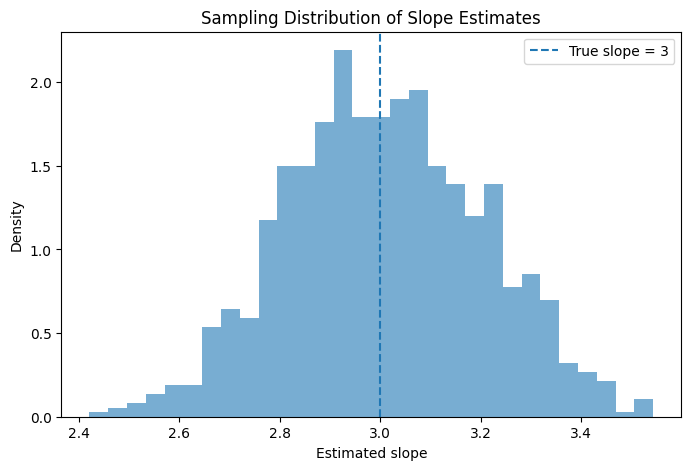

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(slope_estimates, bins=30, density=True, alpha=0.6)
plt.axvline(3, linestyle="--", label="True slope = 3")
plt.xlabel("Estimated slope")
plt.ylabel("Density")
plt.title("Sampling Distribution of Slope Estimates")
plt.legend()
plt.show()

In [11]:
print("Mean slope estimate:", np.mean(slope_estimates))
print("Standard deviation:", np.std(slope_estimates, ddof=1))
print("Last model's standard error:", last_model.bse[1])

Mean slope estimate: 3.008559018262417
Standard deviation: 0.19530083678199672
Last model's standard error: 0.18590056490021203


# Exercise 11 (10 points)

Following the hotel NPV example of Chapter 7, evaluate a 5-year project that costs \$100 (thousand) today. Yearly cash flows are independent and follow a triangular distribution with minimum 15, mode 30, and maximum 45 (thousand). Use a discount rate of 8%, so

$$NPV = -100 + \sum_{t=1}^{5} \frac{CF_t}{(1.08)^t}.$$

- (a) Write a function `simulate_npv(n_iterations, seed)` that returns a `numpy` array of simulated NPVs (one per iteration).
- (b) Run it with 5,000 iterations and `seed = 42`. Report the mean NPV, the standard deviation, the 5th and 95th percentiles, and the probability that NPV $< 0$.
- (c) Compute the Monte Carlo standard error of the mean NPV, $s/\sqrt{N}$. Based on it, should management be confident that the *mean* NPV is positive? Does that mean the project is risk-free? Explain in one or two sentences.

In [12]:
import numpy as np

def simulate_npv(n_iterations, seed):
    np.random.seed(seed)

    cash_flows = np.random.triangular(
        left=15,
        mode=30,
        right=45,
        size=(n_iterations, 5)
    )

    years = np.arange(1, 6)
    discount_factors = 1 / (1.08 ** years)

    npv = -100 + np.sum(
        cash_flows * discount_factors,
        axis=1
    )

    return npv

In [13]:
npv_values = simulate_npv(5000, 42)

mean_npv = np.mean(npv_values)
std_npv = np.std(npv_values, ddof=1)
percentile_5 = np.percentile(npv_values, 5)
percentile_95 = np.percentile(npv_values, 95)
probability_negative = np.mean(npv_values < 0)

print("Mean NPV:", mean_npv)
print("Standard deviation:", std_npv)
print("5th percentile:", percentile_5)
print("95th percentile:", percentile_95)
print("Probability NPV < 0:", probability_negative)

Mean NPV: 19.884407884101087
Standard deviation: 10.985654710023786
5th percentile: 1.8665795507220504
95th percentile: 38.03750575609709
Probability NPV < 0: 0.0354


In [14]:
standard_error_mean = std_npv / np.sqrt(len(npv_values))

print("Monte Carlo standard error:", standard_error_mean)

if mean_npv - 1.96 * standard_error_mean > 0:
    print("The estimated mean NPV is positive with a 95% confidence interval.")
else:
    print("The 95% confidence interval does not establish that mean NPV is positive.")

Monte Carlo standard error: 0.1553606188246351
The estimated mean NPV is positive with a 95% confidence interval.
